# Airline Satisfaction Prediction Project

### Introduction

This project uses Python and Pandas to analyze airline passenger satisfaction data. It explores passenger demographics, flight characteristics, and service ratings to identify factors influencing customer satisfaction.

The dataset contains 22 columns and 129880 rows.

The columns include; 
1. Gender,
2. Customer type,
3. Age,
4. Type of travel,
5. Class,
6. Flight distance,
7. Inflight wifi service,
8. Departure/Arrival time convenient,
9. Ease of online booking,
10. Gate location,
11. Food and drink,
12. Online booking,
13. Seat comfort,
14. Inflight entertainment,
15. On-board service,
16. Leg room service,
17. Baggage handling,
18. Checkin service,
19. Cleanliness,
20. Departure delay in minutes,
21. Arrival delay in minutes, and
22. **Satisfaction.**

> This project aims to **predict the satisfaction of the airline based on the various factors.**

**Libraries import**

In [1]:
# pip install pandas matplotlib seaborn plotly scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Import file** and a glimpse into the data

In [2]:
PATH = "Airline Satisfaction.csv"
print(os.path.exists(PATH))
print(f"{os.path.getsize(PATH) / 1e6:.0f} MB")

True
12 MB


In [3]:
raw = pd.read_csv(PATH, nrows=5)
print(raw.shape)

(5, 22)


In [4]:
raw = pd.read_csv(PATH, decimal=",")
print(raw.shape)

(129880, 22)


In [5]:
raw.head(5)

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [6]:
raw.tail(5)

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
129875,Male,disloyal Customer,34,Business travel,Business,526,3,3,3,1,...,4,4,3,2,4,4,4,0,0.0,False
129876,Male,Loyal Customer,23,Business travel,Business,646,4,4,4,4,...,4,4,4,5,5,5,4,0,0.0,True
129877,Female,Loyal Customer,17,Personal Travel,Eco,828,2,5,1,5,...,2,2,4,3,4,5,2,0,0.0,False
129878,Male,Loyal Customer,14,Business travel,Business,1127,3,3,3,3,...,4,4,3,2,5,4,4,0,0.0,True
129879,Female,Loyal Customer,42,Personal Travel,Eco,264,2,5,2,5,...,2,1,1,2,1,1,1,0,0.0,False


In [7]:
raw.dtypes.value_counts()

int64    16
str       5
bool      1
Name: count, dtype: int64

In [8]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype
---  ------                             --------------   -----
 0   Gender                             129880 non-null  str  
 1   Customer Type                      129880 non-null  str  
 2   Age                                129880 non-null  int64
 3   Type of Travel                     129880 non-null  str  
 4   Class                              129880 non-null  str  
 5   Flight Distance                    129880 non-null  int64
 6   Inflight wifi service              129880 non-null  int64
 7   Departure/Arrival time convenient  129880 non-null  int64
 8   Ease of Online booking             129880 non-null  int64
 9   Gate location                      129880 non-null  int64
 10  Food and drink                     129880 non-null  int64
 11  Online boarding                    129880 non-null  int64
 12  Seat comfort 

In [9]:
raw.describe()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000
mean,39.427957,1190.316392,2.728696,3.057599,2.756876,2.976925,3.204774,3.252633,3.441361,3.358077,3.383023,3.350878,3.632114,3.306267,3.286326,14.713713
std,15.119360,997.452477,1.329340,1.526741,1.401740,1.278520,1.329933,1.350719,1.319289,1.334049,1.287099,1.316252,1.180025,1.266185,1.313682,38.071126
min,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,2.000000,0.000000
50%,40.000000,844.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,0.000000
75%,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,12.000000
max,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000


**Data cleaning**

In [10]:
raw = pd.read_csv(PATH)
NEW_FILE = "Airline_Satisfaction_Updated.csv"

mappings = {
    "Gender": {"Male": 3, "Female": 6}, 
    "Customer Type": {"disloyal Customer": 0, "Loyal Customer": 1},
    "Type of Travel": {"Personal Travel": 0, "Business travel": 1},
    "Class": {"Eco": 1, "Eco Plus": 2, "Business": 3}
    # changing text to numbers for Machine Learning to predict satisfaction
}

for column, mapping in mappings.items():
    raw[column] = raw[column].map(mapping).astype("Int64")

with open(NEW_FILE, "w") as f:
    raw.to_csv(f, index=False)

In [11]:
raw.describe()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.0,129880.0,129880.000000,129880.0,129880.0,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,...,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000
mean,4.522151,0.816908,39.427957,0.690584,2.02965,1190.316392,2.728696,3.057599,2.756876,2.976925,...,3.252633,3.441361,3.358077,3.383023,3.350878,3.632114,3.306267,3.286326,14.713713,15.091129
std,1.499842,0.386743,15.119360,0.462255,0.962636,997.452477,1.329340,1.526741,1.401740,1.278520,...,1.350719,1.319289,1.334049,1.287099,1.316252,1.180025,1.266185,1.313682,38.071126,38.465650
min,3.0,0.0,7.000000,0.0,1.0,31.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,3.0,1.0,27.000000,0.0,1.0,414.000000,2.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,6.0,1.0,40.000000,1.0,2.0,844.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,0.000000,0.000000
75%,6.0,1.0,51.000000,1.0,3.0,1744.000000,4.000000,4.000000,4.000000,4.000000,...,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,12.000000,13.000000
max,6.0,1.0,85.000000,1.0,3.0,4983.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [12]:
raw = pd.read_csv(PATH)
raw.info()
print(raw.isna().sum()[raw.isna().sum() > 0], "missing values")

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  str    
 1   Customer Type                      129880 non-null  str    
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  str    
 4   Class                              129880 non-null  str    
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    129880 non-null

In [13]:
filtered = pd.read_csv(NEW_FILE)
filtered.info()
print(filtered.isna().sum()[filtered.isna().sum() > 0], "missing values")

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  int64  
 1   Customer Type                      129880 non-null  int64  
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  int64  
 4   Class                              129880 non-null  int64  
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    129880 non-null

* Missing values:  
Arrival Delay in Minutes: 393 missing values

In [19]:
# For the empty values, fill with the value immediately before it
filtered["Arrival Delay in Minutes"] = filtered["Arrival Delay in Minutes"].ffill() 

# Convert the column to integer
filtered["Arrival Delay in Minutes"] = filtered["Arrival Delay in Minutes"].astype("int64")

# Save the updated dataset
FINAL_FILE = "Airline_Satisfaction_Final.csv"

with open(FINAL_FILE, "w", newline="") as f:
    filtered.to_csv(f, index=False)

In [32]:
final = pd.read_csv(FINAL_FILE)
final.info()

# Checks for any missing values
missing = final.isna().sum()
missing = missing[missing > 0]
if missing.empty:
    print("Missing values: None")
else:
    print(f"Missing values: {missing}")

# Checks for any duplicates
duplicates = final.duplicated().sum()
print(f"Duplicated rows: {duplicates} rows")

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype
---  ------                             --------------   -----
 0   Gender                             129880 non-null  int64
 1   Customer Type                      129880 non-null  int64
 2   Age                                129880 non-null  int64
 3   Type of Travel                     129880 non-null  int64
 4   Class                              129880 non-null  int64
 5   Flight Distance                    129880 non-null  int64
 6   Inflight wifi service              129880 non-null  int64
 7   Departure/Arrival time convenient  129880 non-null  int64
 8   Ease of Online booking             129880 non-null  int64
 9   Gate location                      129880 non-null  int64
 10  Food and drink                     129880 non-null  int64
 11  Online boarding                    129880 non-null  int64
 12  Seat comfort 



**Data visualisation**

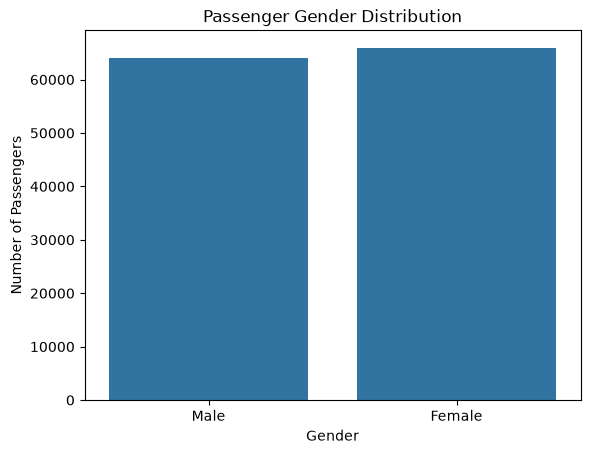

In [33]:
# Gender distribution
sns.countplot(data=raw, x="Gender")

plt.title("Passenger Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

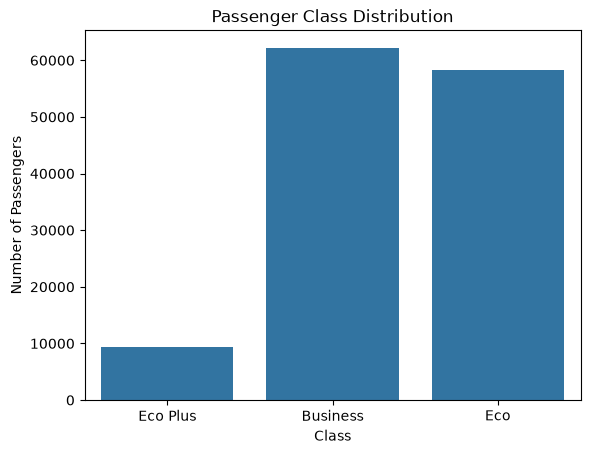

In [35]:
# Passenger class distribution
sns.countplot(data=raw, x="Class")

plt.title("Passenger Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Passengers")
plt.show()

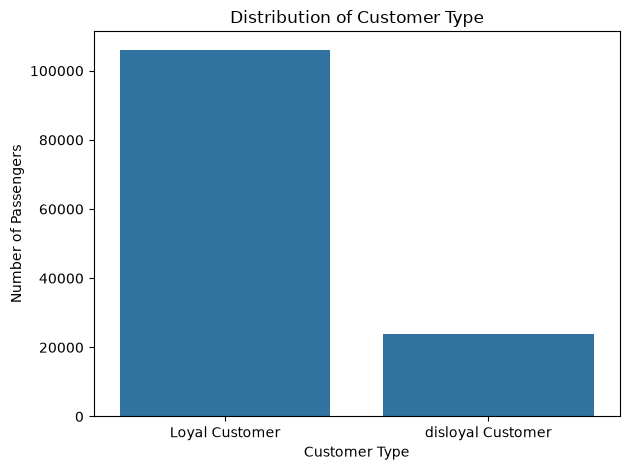

In [60]:
# Customer type distribution
sns.countplot(data=raw, x="Customer Type")

plt.title("Distribution of Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

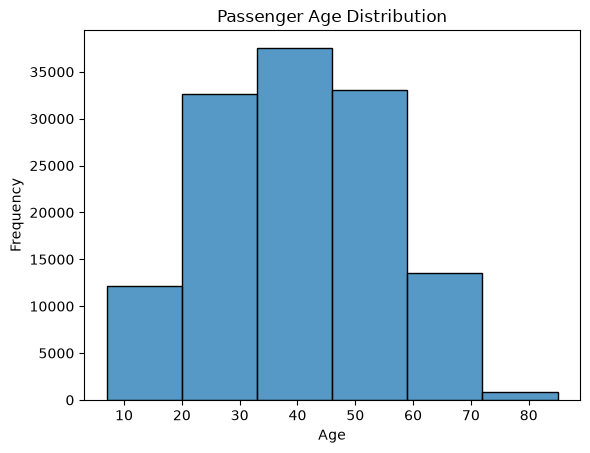

In [67]:
# Age distribution
sns.histplot(data=raw, x="Age", bins=6)

plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

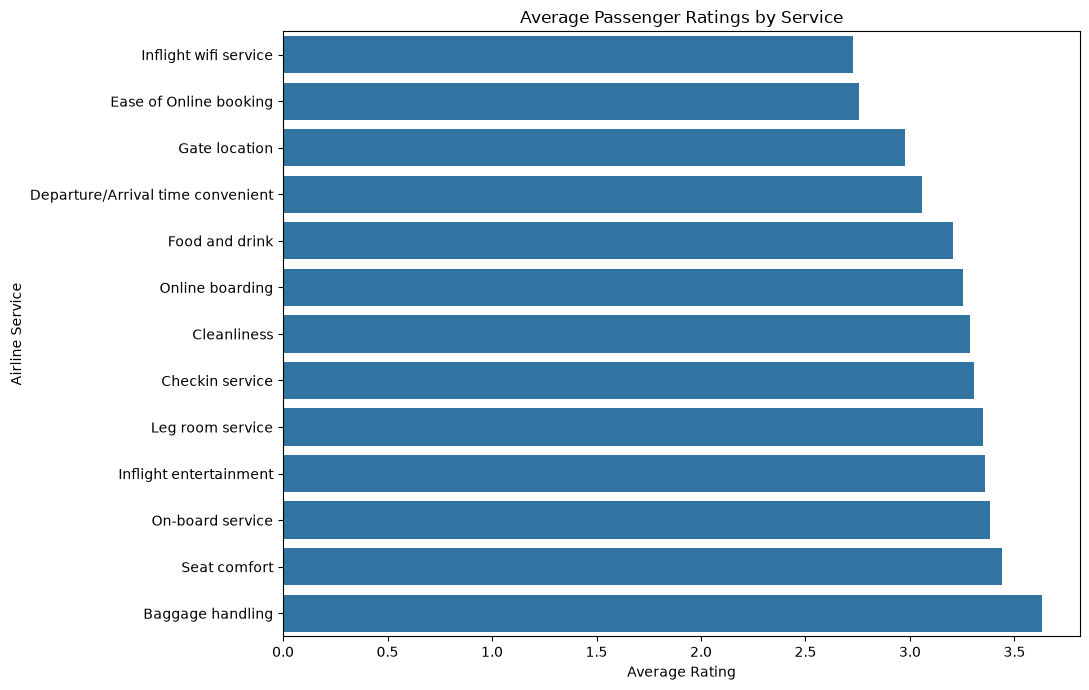

In [47]:
# Mean service quality analysis
service_columns = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

service_means = final[service_columns].mean().sort_values()

plt.figure(figsize=(11, 7))

sns.barplot(
    x=service_means.values,
    y=service_means.index
)

plt.title("Average Passenger Ratings by Service")
plt.xlabel("Average Rating")
plt.ylabel("Airline Service")
plt.tight_layout()
plt.show()

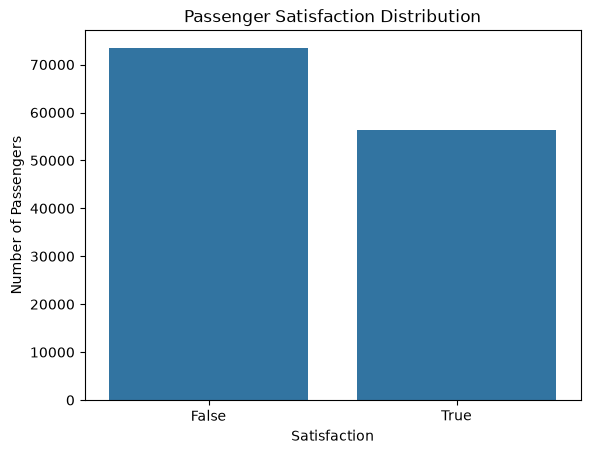

In [49]:
# Overall passenger satisfaction
sns.countplot(data=final, x="satisfaction")

plt.title("Passenger Satisfaction Distribution")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")
plt.show()

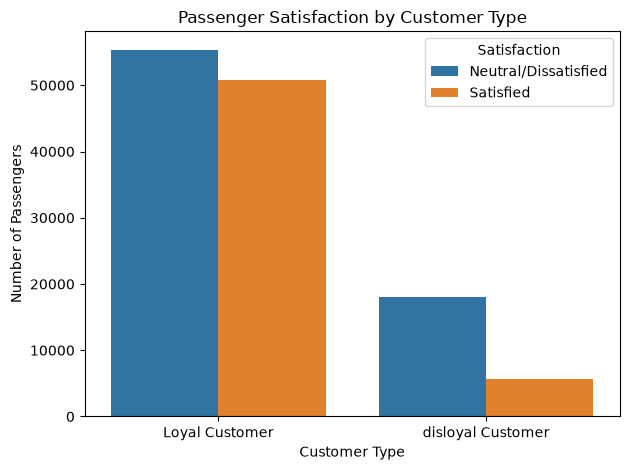

In [59]:
# Satisfaction by customer type
sns.countplot(
    data=raw,
    x="Customer Type",
    hue="satisfaction",
    hue_order=[0, 1]
)

plt.title("Passenger Satisfaction by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Passengers")

plt.legend(
    title="Satisfaction",
    labels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.tight_layout()
plt.show()

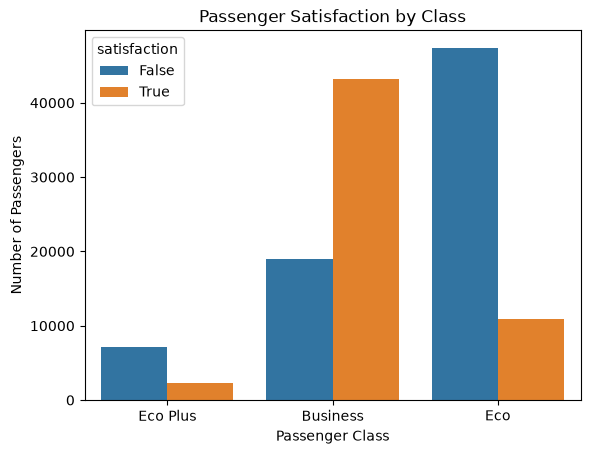

In [50]:
# Satisfaction by passenger class
sns.countplot(data=raw, x="Class", hue="satisfaction")

plt.title("Passenger Satisfaction by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

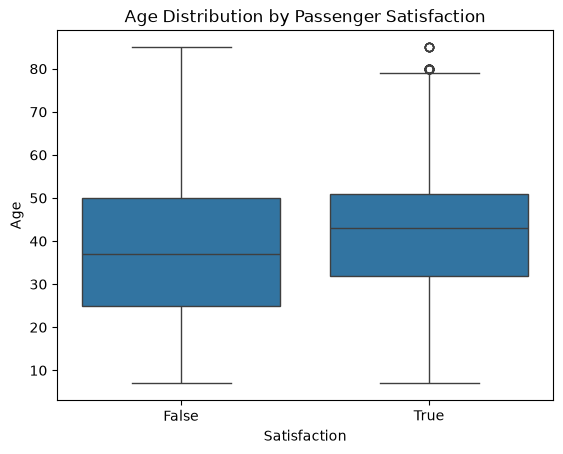

In [51]:
# Satisfaction by age
sns.boxplot(data=final, x="satisfaction", y="Age")

plt.title("Age Distribution by Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Age")
plt.show()

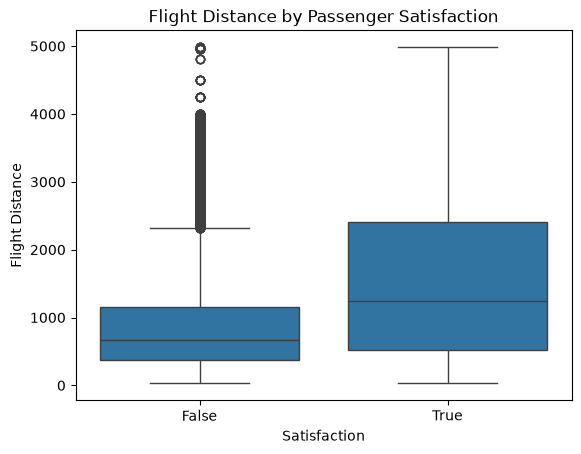

In [14]:
# Satisfaction by flight distance
sns.boxplot(data=final, x="satisfaction", y="Flight Distance")

plt.title("Flight Distance by Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Flight Distance")
plt.show()

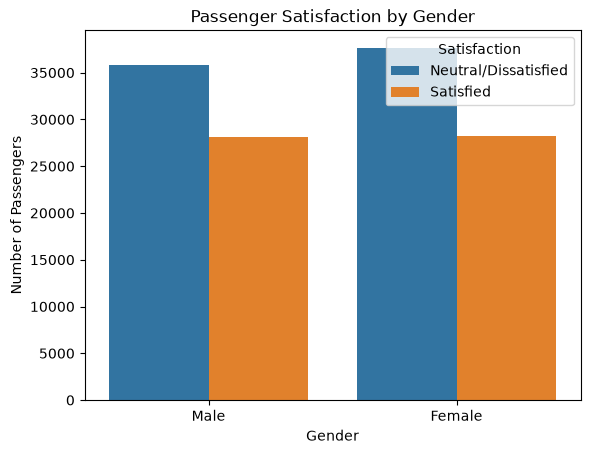

In [40]:
# Satisfaction by gender
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=final,
    x="Gender",
    hue="satisfaction"
)

plt.title("Passenger Satisfaction by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.xticks([0, 1], ["Male", "Female"])
plt.legend(
    title="Satisfaction",
    labels=["Neutral/Dissatisfied", "Satisfied"]
)

plt.show()

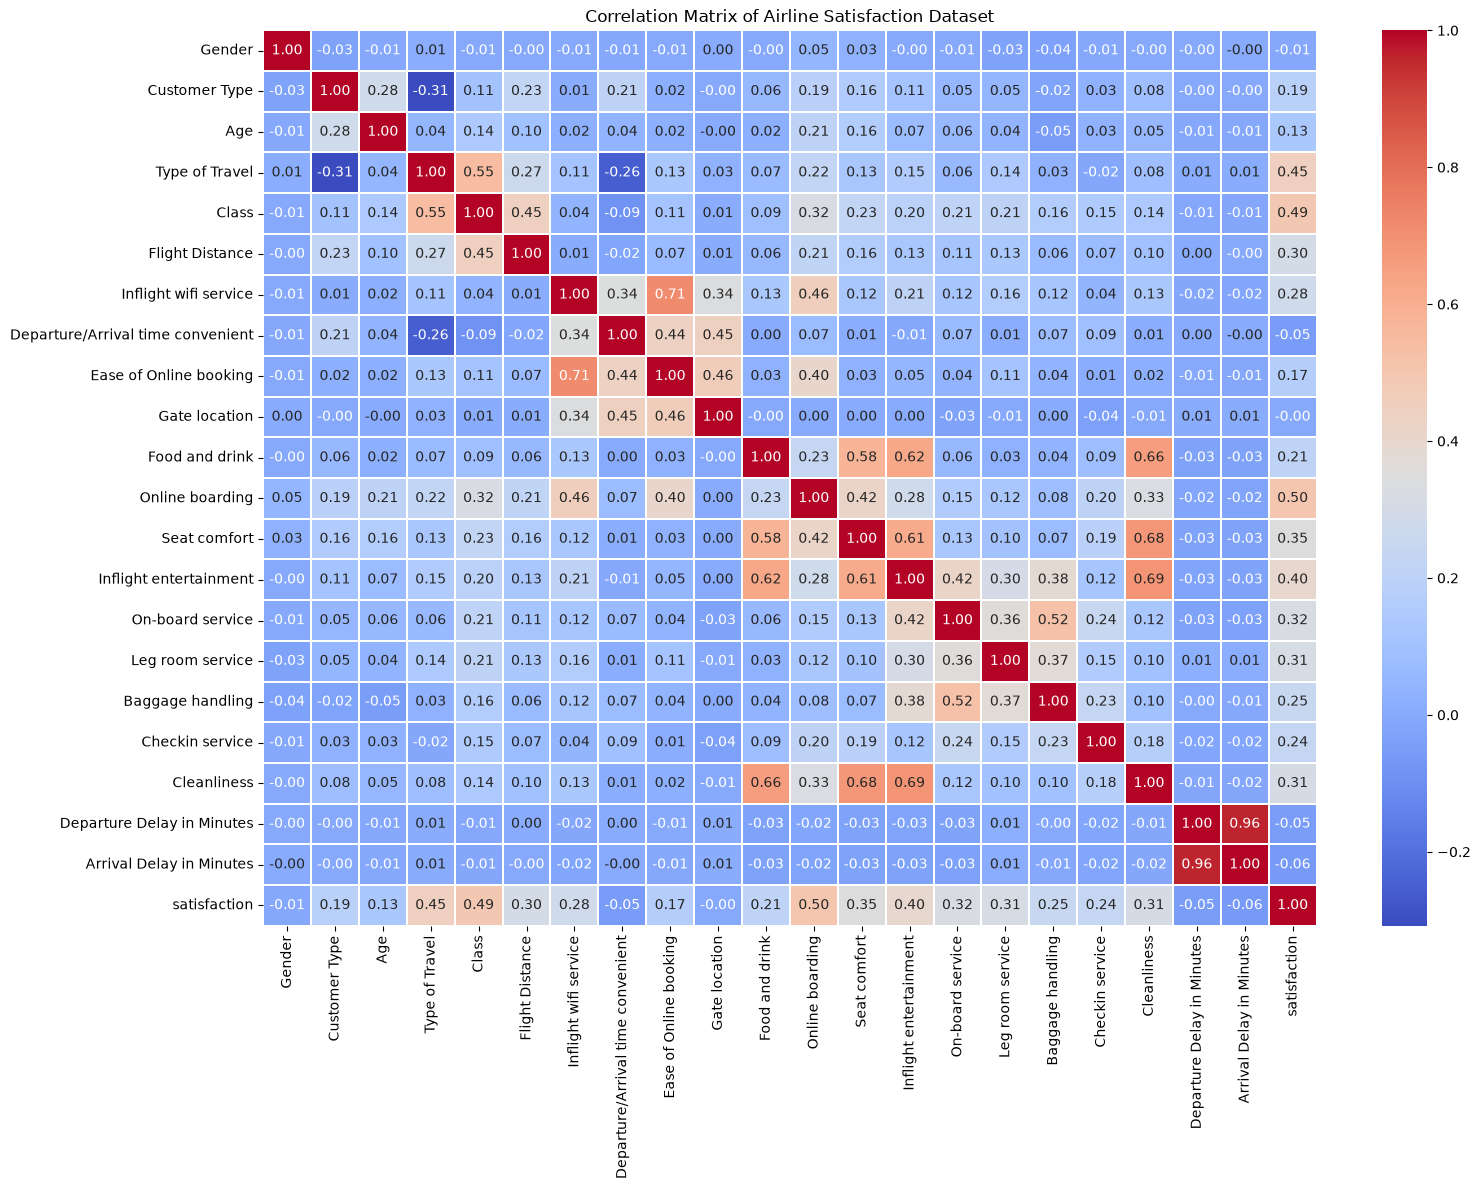

In [53]:
plt.figure(figsize=(16, 12))

correlation = final.corr(numeric_only=True)

sns.heatmap(correlation, cmap="coolwarm", annot=True, fmt=".2f", linewidths=0.3)

plt.title("Correlation Matrix of Airline Satisfaction Dataset")
plt.tight_layout()
plt.show()

At **0.50**, **Online boarding** had the **highest correlation with satisfaction.**
On the other hand, at **0.00, Gate Location** showed **no correlation with satisfaction.**
The highest variable-to-variable correlation was observed between Departure and Arrival delay. **At 0.96, the data show a near-perfect correlation, with a flight delay in departure translating into a delay in its arrival.**